# PaySim fraud detection: 02 features, models and evaluation

**Goal:** turn the findings from `01_data_and_eda.ipynb` into features, train models that catch fraud, and check that the scores are real.

**This notebook:**
1. Load the data
2. Features: which ones could a bank know *before* the money moves?
3. Train/test split and scaling
4. First models with all features: too good to be true?
5. Leakage check: which features give the answer away?
6. Realistic models: safe features and class weights
7. Comparison: which model is best?
8. Evaluation: confusion matrix, precision-recall curve, cost-based threshold, feature importance
9. Future work

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay)

pd.set_option("display.float_format", "{:,.3f}".format)

# 1. Load the data

Same steps as in notebook 01: rename the column and keep only TRANSFER and CASH_OUT, the only types with fraud.

In [2]:
df = pd.read_csv("paysim.csv")
df = df.rename(columns={"oldbalanceOrg": "oldbalanceOrig"})

tc = df[df["type"].isin(["TRANSFER", "CASH_OUT"])].copy()
tc.shape

(2770409, 11)

# 2. Features: which ones could a bank know before the money moves?

Each feature comes from a finding in notebook 01. A bank wants to stop fraud **before** the payment goes through, so I split them into two groups:

| Feature | Meaning | From finding | Known before? |
|---|---|---|---|
| `is_transfer` | 1 if TRANSFER, 0 if CASH_OUT | transfers have a higher fraud rate | safe |
| `log_amount` | log of the amount | amounts are very skewed | safe |
| `oldbalanceOrig` | balance before the transaction | strongest correlation | safe |
| `hour` | hour of the day | fraud peaks at night | safe |
| `emptied` | 1 if the account is left at 0 | 98% of frauds | uses `newbalanceOrig` |
| `mismatch` | 1 if old balance − amount ≠ new balance | balances that don't add up | uses `newbalanceOrig` |
| `zero_balance` | 1 if the destination's balance is 0 before and after | money goes to "empty" accounts | uses `newbalanceDest` |

I drop `nameOrig` / `nameDest` (IDs), `step` (replaced by `hour`) and `isFlaggedFraud` (the bank's rule, my baseline).

In [3]:
tc["is_transfer"] = (tc["type"] == "TRANSFER").astype(int)
tc["log_amount"] = np.log1p(tc["amount"])
tc["hour"] = tc["step"] % 24

tc["emptied"] = (tc["newbalanceOrig"] == 0).astype(int)
tc["mismatch"] = ((tc["oldbalanceOrig"] - tc["amount"] - tc["newbalanceOrig"]).abs() > 0.01).astype(int)
tc["zero_balance"] = ((tc["oldbalanceDest"] == 0) & (tc["newbalanceDest"] == 0)).astype(int)

In [4]:
safe_features = ["is_transfer", "log_amount", "oldbalanceOrig", "hour"]
after_features = ["emptied", "mismatch", "zero_balance"]
all_features = safe_features + after_features

tc[all_features + ["isFraud"]].head()

,is_transfer,log_amount,oldbalanceOrig,hour,emptied,mismatch,zero_balance,isFraud
2,1,5.204,181.000,1,1,0,1,1
3,0,5.204,181.000,1,1,0,0,1
15,0,12.342,"15,325.000",1,1,1,0,0
19,1,12.280,705.000,1,1,1,0,0
24,1,12.650,"10,835.000",1,1,1,0,0


# 3. Train/test split and scaling

I use a **stratified** split so train and test keep the same small share of fraud (about 0.3% in TRANSFER + CASH_OUT).

In [5]:
X = tc[all_features]
y = tc["isFraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Fraud % in train:", round(y_train.mean() * 100, 3))
print("Fraud % in test:", round(y_test.mean() * 100, 3))

Fraud % in train: 0.296
Fraud % in test: 0.297


Logistic Regression needs features on a similar scale. Balances have huge outliers, so I use **RobustScaler** (median and IQR, so outliers don't squash everything else). It is **fit on the training set only**, so no information from the test set leaks in. Tree models don't need scaling.

In [6]:
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. First models with all features: too good to be true?

Three models with default settings:
- **Logistic Regression**: simple, fast, easy to explain
- **Random Forest**: many decision trees voting together
- **XGBoost**: trees built one after another, each fixing the last one's mistakes

For each one I record precision, recall, F1 and **average precision** (area under the precision-recall curve, good when one class is rare).

In [7]:
results_all = []

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)
y_pred = lr.predict(X_test_scaled)
y_prob = lr.predict_proba(X_test_scaled)[:, 1]
results_all.append({"model": "Logistic Regression",
                    "precision": precision_score(y_test, y_pred),
                    "recall": recall_score(y_test, y_pred),
                    "f1": f1_score(y_test, y_pred),
                    "avg_precision": average_precision_score(y_test, y_prob)})

rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]
results_all.append({"model": "Random Forest",
                    "precision": precision_score(y_test, y_pred),
                    "recall": recall_score(y_test, y_pred),
                    "f1": f1_score(y_test, y_pred),
                    "avg_precision": average_precision_score(y_test, y_prob)})

xgb = XGBClassifier(random_state=42)
xgb.fit(X_train, y_train)
y_pred = xgb.predict(X_test)
y_prob = xgb.predict_proba(X_test)[:, 1]
results_all.append({"model": "XGBoost",
                    "precision": precision_score(y_test, y_pred),
                    "recall": recall_score(y_test, y_pred),
                    "f1": f1_score(y_test, y_pred),
                    "avg_precision": average_precision_score(y_test, y_prob)})

pd.DataFrame(results_all)

,model,precision,recall,f1,avg_precision
0,Logistic Regression,0.999,0.995,0.997,0.995
1,Random Forest,0.998,0.997,0.998,0.997
2,XGBoost,0.999,0.995,0.997,0.995


All three models score close to **1.00**. On a problem as hard as fraud, that is a warning sign, not a win. Before trusting it, I check for **leakage**: information in the features that the model wouldn't really have at prediction time.

# 5. Leakage check: which features give the answer away?

### 5a. How good is each feature on its own?
I train a Logistic Regression on **one feature at a time**. I look at **average precision**, not only precision and recall: with only 0.3% fraud, a one-feature model often never reaches the 0.5 cut-off, so precision and recall show 0 even when the feature is useful.

In [8]:
single = []

for feature in all_features:
    col = all_features.index(feature)
    X_train_one = X_train_scaled[:, [col]]
    X_test_one = X_test_scaled[:, [col]]

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train_one, y_train)
    y_pred = model.predict(X_test_one)
    y_prob = model.predict_proba(X_test_one)[:, 1]
    single.append({"feature": feature,
                   "precision": precision_score(y_test, y_pred, zero_division=0),
                   "recall": recall_score(y_test, y_pred),
                   "avg_precision": average_precision_score(y_test, y_prob)})

pd.DataFrame(single).sort_values("avg_precision", ascending=False)

,feature,precision,recall,avg_precision
6,zero_balance,0.696,0.499,0.349
2,oldbalanceOrig,0.690,0.195,0.295
5,mismatch,0.000,0.000,0.030
3,hour,0.000,0.000,0.025
1,log_amount,0.000,0.000,0.020
0,is_transfer,0.000,0.000,0.005
4,emptied,0.000,0.000,0.003


_The strongest feature on its own is zero_balance (AP 0.35), which uses balances after the transaction. The second is oldbalanceOrig (AP 0.30), which is known before. The rest are close to random (~0.003). No single feature gets anywhere near 1.00, so the leakage must come from a combination of features._

### 5b. What happens with only the safe features?

In [9]:
safe_cols = [all_features.index(f) for f in safe_features]

lr_safe = LogisticRegression(max_iter=1000)
lr_safe.fit(X_train_scaled[:, safe_cols], y_train)
y_pred = lr_safe.predict(X_test_scaled[:, safe_cols])

print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))

Precision: 0.709
Recall: 0.203


With only the safe features, Logistic Regression drops to about **precision 0.7 / recall 0.2**. So no single feature leaks alone, but **together the after-transaction features give the answer away**: they describe what happened to the balances *after* the payment, and in PaySim fraud always moves money in the same pattern (take the full balance, balances add up exactly).

**Decision:** from here I only use the safe features, so the scores reflect what a bank could really do before approving a payment.

_Removing the 3 after-transaction features drops recall from about 1.00 to 0.20, which shows how much they were giving away. Another possible leak is paired frauds (a TRANSFER and its CASH_OUT from the same fraud), because a random split can put one in train and the other in test. I check this later with a time-based split (section 9)._

# 6. Realistic models: safe features and class weights

With 0.3% fraud, models learn mostly from normal transactions. **Class weights** make each fraud count more during training:
- Logistic Regression and Random Forest: `class_weight="balanced"`
- XGBoost: `scale_pos_weight` = number of normal ÷ number of fraud

In [10]:
X_train_safe = X_train[safe_features]
X_test_safe = X_test[safe_features]

scaler_safe = RobustScaler()
X_train_safe_scaled = scaler_safe.fit_transform(X_train_safe)
X_test_safe_scaled = scaler_safe.transform(X_test_safe)

weight = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(weight, 1))

scale_pos_weight: 336.3


In [11]:
results = []

lr_w = LogisticRegression(max_iter=1000, class_weight="balanced")
lr_w.fit(X_train_safe_scaled, y_train)
y_pred = lr_w.predict(X_test_safe_scaled)
lr_prob = lr_w.predict_proba(X_test_safe_scaled)[:, 1]
results.append({"model": "Logistic Regression (balanced)",
                "precision": precision_score(y_test, y_pred),
                "recall": recall_score(y_test, y_pred),
                "f1": f1_score(y_test, y_pred),
                "avg_precision": average_precision_score(y_test, lr_prob)})

In [12]:
rf_w = RandomForestClassifier(n_estimators=100, class_weight="balanced", n_jobs=-1, random_state=42)
rf_w.fit(X_train_safe, y_train)
y_pred = rf_w.predict(X_test_safe)
rf_prob = rf_w.predict_proba(X_test_safe)[:, 1]
results.append({"model": "Random Forest (balanced)",
                "precision": precision_score(y_test, y_pred),
                "recall": recall_score(y_test, y_pred),
                "f1": f1_score(y_test, y_pred),
                "avg_precision": average_precision_score(y_test, rf_prob)})

In [13]:
xgb_w = XGBClassifier(scale_pos_weight=weight, random_state=42)
xgb_w.fit(X_train_safe, y_train)
y_pred = xgb_w.predict(X_test_safe)
xgb_prob = xgb_w.predict_proba(X_test_safe)[:, 1]
results.append({"model": "XGBoost (weighted)",
                "precision": precision_score(y_test, y_pred),
                "recall": recall_score(y_test, y_pred),
                "f1": f1_score(y_test, y_pred),
                "avg_precision": average_precision_score(y_test, xgb_prob)})

# 7. Comparison: which model is best for fraud?

The bank's rule for reference: **precision 1.00, recall 0.002**.

In [14]:
results_df = pd.DataFrame(results)
results_df.round(3)

,model,precision,recall,f1,avg_precision
0,Logistic Regression (balanced),0.028,0.851,0.054,0.282
1,Random Forest (balanced),0.762,0.777,0.770,0.854
2,XGBoost (weighted),0.246,0.990,0.395,0.861


_I pick XGBoost. It has the highest average precision (0.861), so it ranks fraud best regardless of the cut-off, and it catches 99% of fraud. Its precision at 0.5 is low (0.25), so there are many false alarms, but I fix that later by choosing the threshold based on cost. Random Forest is close on AP (0.854) and has better precision, but misses more fraud (recall 0.78). Logistic Regression is far behind (AP 0.28), probably because the fraud pattern isn’t a straight line. (All three models use class weights: “balanced” in sklearn and scale_pos_weight in XGBoost do the same thing.)_.

# 8. Evaluation

### 8a. Where does the model go wrong? (confusion matrix)

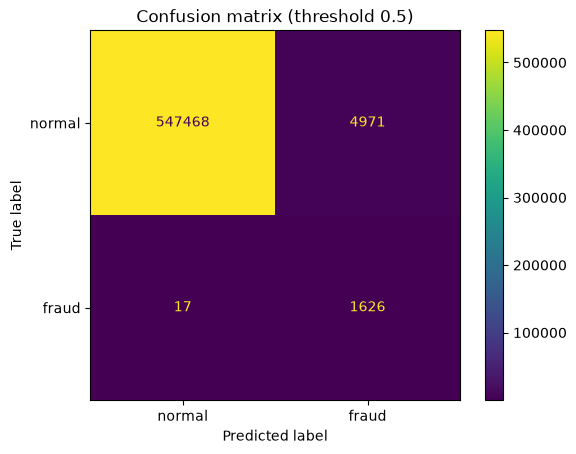

In [15]:
best_prob = xgb_prob
best_pred = (best_prob >= 0.5).astype(int)

ConfusionMatrixDisplay.from_predictions(y_test, best_pred, display_labels=["normal", "fraud"])
plt.title("Confusion matrix (threshold 0.5)")
plt.show()

_At 0.5, XGBoost catches 1,626 of 1,643 frauds and misses only 17. The price is 4,971 false alarms, about 3 for every fraud caught. That’s out of 552k normal transactions, so less than 1% of customers are bothered._

### 8b. How do precision and recall trade off? (precision-recall curve)

Each point on the curve is a different threshold. A curve closer to the top right is better.

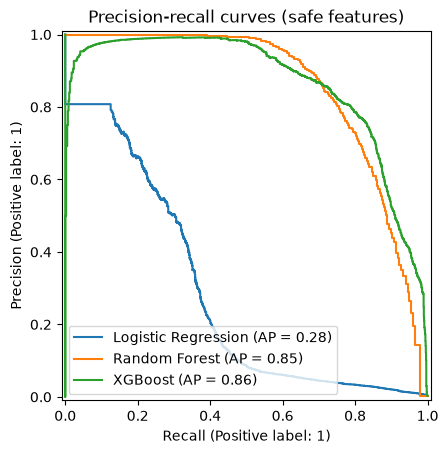

In [16]:
ax = plt.gca()
PrecisionRecallDisplay.from_predictions(y_test, lr_prob, name="Logistic Regression", ax=ax)
PrecisionRecallDisplay.from_predictions(y_test, rf_prob, name="Random Forest", ax=ax)
PrecisionRecallDisplay.from_predictions(y_test, xgb_prob, name="XGBoost", ax=ax)
plt.title("Precision-recall curves (safe features)")
plt.show()

_XGBoost and Random Forest are almost the same and far above Logistic Regression. Precision stays near 1.0 until about 50% recall, then falls quickly after about 75–80% recall. Catching the last frauds costs a lot of false alarms._

### 8c. Which threshold costs the bank the least?

0.5 is just a default. A bank cares about **money**, so I pick the threshold with the lowest total cost. My assumptions:
- **Missed fraud** (false negative): the bank loses the transaction amount
- **False alarm** (false positive): a fixed cost of **50** for a staff check and an annoyed customer

I try thresholds from 0.05 to 0.95 and add up the cost for each one.

In [17]:
amounts = tc.loc[X_test.index, "amount"]
false_alarm_cost = 50

costs = []

for t in np.arange(0.05, 1.0, 0.05):
    pred = (best_prob >= t).astype(int)
    missed_cost = amounts[(pred == 0) & (y_test == 1)].sum()
    alarm_cost = ((pred == 1) & (y_test == 0)).sum() * false_alarm_cost
    costs.append({"threshold": round(t, 2),
                  "precision": precision_score(y_test, pred, zero_division=0),
                  "recall": recall_score(y_test, pred),
                  "total_cost": missed_cost + alarm_cost})

costs_df = pd.DataFrame(costs)
costs_df

,threshold,precision,recall,total_cost
0,0.050,0.096,0.996,"2,570,517.350"
1,0.100,0.119,0.996,"2,403,718.350"
2,0.150,0.136,0.995,"2,319,123.350"
3,0.200,0.153,0.995,"2,253,073.350"
4,0.250,0.166,0.994,"2,217,668.080"
5,0.300,0.178,0.993,"2,184,624.080"
6,0.350,0.187,0.992,"2,168,868.810"
7,0.400,0.210,0.991,"2,261,442.480"
8,0.450,0.222,0.990,"2,573,086.760"
9,0.500,0.246,0.990,"2,536,186.760"


threshold            0.350
precision            0.187
recall               0.992
total_cost   2,168,868.810
Name: 6, dtype: float64


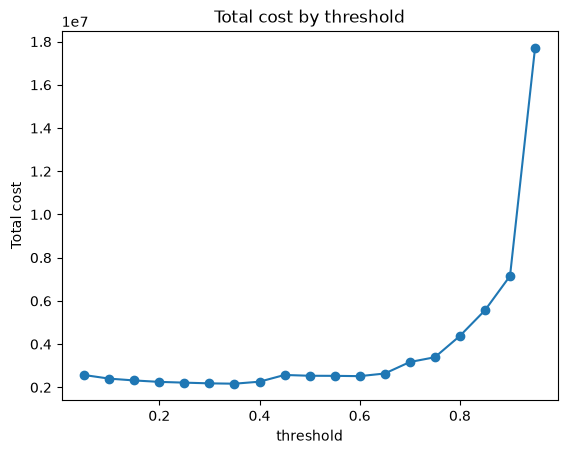

In [18]:
best_row = costs_df.loc[costs_df["total_cost"].idxmin()]
print(best_row)

costs_df.plot(x="threshold", y="total_cost", marker="o", legend=False)
plt.ylabel("Total cost")
plt.title("Total cost by threshold")
plt.show()

_The cheapest threshold is 0.35 (about 2.17M total cost). Compared with 0.5, recall rises slightly (0.990 → 0.992) and precision falls (0.25 → 0.19). With a false alarm at only 50, catching one more fraud is worth many extra alarms. The cost is flat between 0.2 and 0.65 and rises sharply after 0.8, when missed frauds pile up. If a false alarm cost more, the best threshold would move up: my sensitivity chart gives about 0.35 / 0.65 / 0.9 for a false alarm cost of 50 / 500 / 5000. So the threshold is a business decision._

### 8d. Which features matter most? (feature importance)

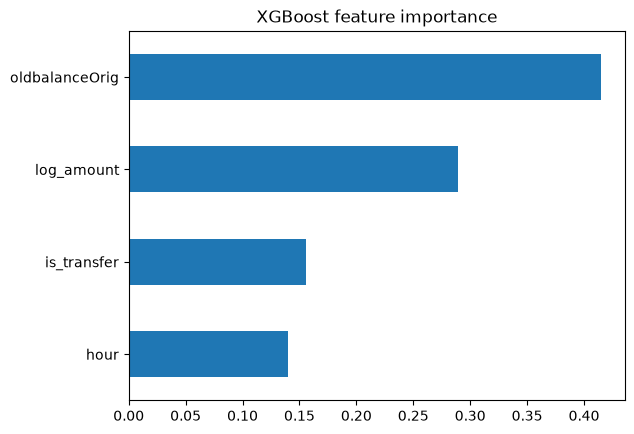

In [19]:
importance = pd.Series(xgb_w.feature_importances_, index=safe_features).sort_values()
importance.plot(kind="barh")
plt.title("XGBoost feature importance")
plt.show()

_Mostly yes. oldbalanceOrig is the most important feature (~0.41), which matches notebook 01: fraud targets accounts with money in them and empties them. log_amount is second (~0.29), because fraud amounts tend to be bigger. is_transfer (~0.16) and hour (~0.14) still matter, which matches transfer vs cash out and the night peak, but less than the money features. Note that XGBoost importance shows how much the model uses a feature, not whether it raises or lowers fraud risk. SHAP would show that (future work)._

# 9. Time-based split
So far the split was random, so train and test both came from the whole month. Here I train on the first 80% of steps and test on the last 20%, like a bank scoring new transactions. This also keeps paired frauds on one side of the split.

In [20]:
from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score, precision_score, recall_score

features = ["is_transfer", "log_amount", "oldbalanceOrig", "hour"]

split_step = tc["step"].quantile(0.8)

train_mask = tc["step"] <= split_step
test_mask = tc["step"] > split_step

train = tc[train_mask]
test = tc[test_mask]

X_train_time = train[features]
y_train_time = train["isFraud"]
X_test_time = test[features]
y_test_time = test["isFraud"]

weight_time = (y_train_time == 0).sum() / (y_train_time == 1).sum()

xgb_time = XGBClassifier(scale_pos_weight=weight_time, random_state=42)
xgb_time.fit(X_train_time, y_train_time)

proba_time = xgb_time.predict_proba(X_test_time)[:, 1]
pred_time = (proba_time >= 0.5).astype(int)

print("Precision:", round(precision_score(y_test_time, pred_time), 3))
print("Recall:", round(recall_score(y_test_time, pred_time), 3))
print("AP:", round(average_precision_score(y_test_time, proba_time), 3))

Precision: 0.43
Recall: 0.975
AP: 0.886


_I compared a random split with a time-based split (train on the first 80% of steps, test on the last 20%), using the same XGBoost and safe features._
| Split | Precision | Recall | AP |
|---|---|---|---|
| Random | 0.25 | 0.99 | 0.86 |
| Time-based | 0.43 | 0.975 | 0.89 |

_Recall stays very high, so the model still catches almost all fraud in later transactions it has never seen. The random split does not look too optimistic. Precision and AP are higher with the time split, probably because the later steps have a bigger share of fraud, so the two results are not directly comparable. The time split is still the more realistic test, because a bank always predicts future transactions._

# 10. Future work
- **Cross-validation and tuning:** 5-fold `TimeSeriesSplit` and `RandomizedSearchCV` with `scoring="average_precision"`, so each fold trains on the past and tests on the future.
- **Resampling:** try SMOTE on the training set only and compare with class weights.
- **Probability calibration:** make the predicted probabilities match real fraud rates, so the cost-based threshold is more reliable.
- **SHAP:** explain single predictions, not just overall importance.
- **MLflow:** log each model's settings and scores to compare experiments.